# The MST and the terrain along it

Two views of one instance in one city:

- **`plot_mst(city, benchmark)`** draws the minimum spanning tree with every site coloured by its elevation.
- **`plot_profile(city, benchmark, a, b)`** gives the sagittal view: elevation against distance along the
  MST path from site `a` to site `b`, through every intermediate site and every ~100 m sample point.
  It shows how much the path undulates, not just how far apart its ends are.

The benchmark is a Solomon name such as `"r101"`, or an extended one such as `"r101_200"` (Solomon plus
100 stores, from `extend.py`). `benchmarks(city)` lists what has been generated for a city.
Sites are numbered as in the solver: 0-based, with the depot at 0. The `id` column of the instance CSV is
the same number plus 1. In an extended instance, sites 1-100 are the original customers and 101 onwards are
the added stores. These are drawn as triangles, and their roads, the spurs added to the original MST, are
drawn lighter.

Everything comes from the generated files, so no DEM is needed:
- the site elevations come from `instances/<City>/<City>_5_<benchmark>.csv`;
- the tree and the 100 m profiles come from `edge_profiles/<City>_5_<benchmark>.csv`.

Each row of the edge-profile file is one ~100 m segment with its rise `dz`, so the elevation at each sample
point is the site elevation at the start of the edge plus the running sum of `dz`.

In [1]:
from collections import deque
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").is_dir())
PROCESSED = ROOT / "data" / "processed"
SCALE = 5

# sequential: one hue, light (low) to dark (high), starting light enough to stay visible on white
ELEVATION_CMAP = LinearSegmentedColormap.from_list("elevation", plt.cm.Blues(np.linspace(0.25, 1.0, 256)))
INK, MUTED, GRID = "#1f2328", "#6e7781", "#d0d7de"
PATH_COLOUR = "#c2410c"   # the chosen path, one accent against the blue sites

## Load an instance

In [2]:
def load(city, benchmark):
    """Sites, edge-profile segments and the tree's adjacency for one instance in one city."""
    stem = f"{city}_{SCALE}_{benchmark}"
    sites = pd.read_csv(PROCESSED / "instances" / city / f"{stem}.csv")
    segments = pd.read_csv(PROCESSED / "edge_profiles" / f"{stem}.csv")
    adjacent = {i: [] for i in range(len(sites))}
    for u, v in segments[["start", "end"]].drop_duplicates().itertuples(index=False):
        adjacent[u].append(v)
        adjacent[v].append(u)
    by_edge = {edge: g[["length", "dz"]].to_numpy() for edge, g in segments.groupby(["start", "end"], sort=False)}
    # an extended benchmark (e.g. r101_200) starts with its base's sites; the rest are added stores
    base = benchmark.rsplit("_", 1)[0]
    base_file = PROCESSED / "instances" / city / f"{city}_{SCALE}_{base}.csv"
    n_base = len(pd.read_csv(base_file)) if base != benchmark and base_file.exists() else len(sites)
    return dict(city=city, benchmark=benchmark, sites=sites, segments=by_edge, adjacent=adjacent, n_base=n_base)


def benchmarks(city):
    """The benchmarks generated for a city, Solomon and extended."""
    prefix = f"{city}_{SCALE}_"
    return sorted(p.stem[len(prefix):] for p in (PROCESSED / "instances" / city).glob(f"{prefix}*.csv"))


def tree_path(inst, a, b):
    """The sites on the MST path from a to b, both ends included."""
    previous = {a: None}
    queue = deque([a])
    while queue:
        u = queue.popleft()
        for v in inst["adjacent"][u]:
            if v not in previous:
                previous[v] = u
                queue.append(v)
    path = [b]
    while path[-1] != a:
        path.append(previous[path[-1]])
    return path[::-1]

## The MST, sites coloured by elevation

In [3]:
def plot_mst(city, benchmark, path=None, ax=None):
    """The tree, with sites coloured by elevation; optionally highlight a path (a list of sites)."""
    inst = load(city, benchmark) if isinstance(city, str) else city
    s = inst["sites"]
    xy = s[["scaled_x", "scaled_y"]].to_numpy(float) / 1000
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 8))
    nb = inst["n_base"]
    original = [[xy[u], xy[v]] for (u, v) in inst["segments"] if u < nb and v < nb]
    spurs    = [[xy[u], xy[v]] for (u, v) in inst["segments"] if u >= nb or v >= nb]
    ax.add_collection(LineCollection(original, colors="#8c959f", linewidths=1.0, zorder=1))
    ax.add_collection(LineCollection(spurs, colors=GRID, linewidths=0.8, zorder=1))
    size = 36 if len(s) <= 101 else 22
    norm = plt.Normalize(s.elevation.min(), s.elevation.max())
    sc = ax.scatter(xy[1:nb, 0], xy[1:nb, 1], c=s.elevation[1:nb], cmap=ELEVATION_CMAP, norm=norm, s=size,
                    edgecolors="white", linewidths=0.6, zorder=3, label="original customer")
    if nb < len(s):
        ax.scatter(xy[nb:, 0], xy[nb:, 1], c=s.elevation[nb:], cmap=ELEVATION_CMAP, norm=norm, s=size + 8,
                   marker="^", edgecolors=INK, linewidths=0.5, zorder=3, label="added store")
        ax.legend(frameon=False, loc="upper left", fontsize=9, bbox_to_anchor=(0, -0.08), ncol=2)
    ax.scatter(*xy[0], marker="s", s=90, c=[ELEVATION_CMAP((s.elevation[0] - s.elevation.min())
                                                          / np.ptp(s.elevation))],
               edgecolors=INK, linewidths=1.2, zorder=4)
    ax.annotate("depot", xy[0], xytext=(8, 8), textcoords="offset points", color=INK, fontsize=9)
    if path is not None:
        ax.plot(xy[path, 0], xy[path, 1], color=PATH_COLOUR, lw=2, zorder=2)
        for end in (path[0], path[-1]):
            ax.annotate(str(end), xy[end], xytext=(6, -12), textcoords="offset points",
                        color=INK, fontsize=10, fontweight="bold")
    cb = plt.colorbar(sc, ax=ax, shrink=0.75)
    cb.set_label("elevation (m)", color=MUTED)
    ax.set_aspect("equal")
    ax.set_xlabel("km", color=MUTED); ax.set_ylabel("km", color=MUTED)
    ax.tick_params(colors=MUTED)
    for spine in ax.spines.values():
        spine.set_color(GRID)
    total = sum(seg[:, 0].sum() for seg in inst["segments"].values()) / 1000
    ax.set_title(f"{inst['city']} {inst['benchmark']}: {len(s) - 1} customers, network {total:.1f} km, "
                 f"elevation {s.elevation.min():.0f}-{s.elevation.max():.0f} m", color=INK, loc="left")
    return ax

## The sagittal view between two sites

For each MST edge on the path, the segments are walked forwards (or backwards, with `dz` negated, when the
path runs end → start, as the solver does), starting from the elevation of the site the edge leaves.

In [4]:
def path_profile(inst, a, b):
    """Distance along the path (m) and elevation (m) at every sample point, and which points are sites."""
    path = tree_path(inst, a, b)
    elevation = inst["sites"].elevation.to_numpy()
    rows = [dict(distance=0.0, elevation=elevation[a], site=a)]
    for u, v in zip(path[:-1], path[1:]):
        if (u, v) in inst["segments"]:
            seg = inst["segments"][(u, v)]
        else:
            seg = inst["segments"][(v, u)][::-1] * [1, -1]
        z = elevation[u] + np.cumsum(seg[:, 1])
        d = rows[-1]["distance"] + np.cumsum(seg[:, 0])
        rows += [dict(distance=di, elevation=zi, site=None) for di, zi in zip(d[:-1], z[:-1])]
        rows.append(dict(distance=d[-1], elevation=elevation[v], site=v))   # land exactly on the site
    return path, pd.DataFrame(rows)


def plot_profile(city, benchmark, a, b, show_map=True):
    """Elevation along the MST path from site a to site b (0-based, depot 0)."""
    inst = load(city, benchmark)
    path, p = path_profile(inst, a, b)
    xy = inst["sites"][["scaled_x", "scaled_y"]].to_numpy(float)
    rise = np.diff(p.elevation)
    run = np.diff(p.distance)
    grade = 100 * rise / np.where(run > 0, run, np.nan)   # NaN on a zero-length road (co-located stores)
    steepest = lambda f: float(f(grade)) if np.isfinite(grade).any() else 0.0
    stats = dict(path_km=p.distance.iloc[-1] / 1000,
                 straight_km=np.hypot(*(xy[b] - xy[a])) / 1000,
                 sites_on_path=len(path) - 2,
                 climb_m=rise[rise > 0].sum(), descent_m=abs(rise[rise < 0].sum()),
                 net_m=p.elevation.iloc[-1] - p.elevation.iloc[0],
                 steepest_up_pct=steepest(np.nanmax), steepest_down_pct=steepest(np.nanmin))

    if show_map:
        fig, (ax_map, ax) = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw=dict(width_ratios=[1, 1.6]))
        plot_mst(inst, None, path=path, ax=ax_map)
        ax_map.set_title(f"{city} {benchmark}: path {a} → {b}", color=INK, loc="left")
    else:
        fig, ax = plt.subplots(figsize=(11, 4.5))

    km = p.distance / 1000
    ax.fill_between(km, p.elevation, p.elevation.min() - 2, color=PATH_COLOUR, alpha=0.08, lw=0)
    ax.plot(km, p.elevation, color=PATH_COLOUR, lw=2, zorder=2)
    samples = p[p.site.isna()]
    ax.scatter(samples.distance / 1000, samples.elevation, s=10, color=PATH_COLOUR, zorder=3,
               label="~100 m sample")
    on = p[p.site.notna()]
    added = on.site >= inst["n_base"]
    ax.scatter(on.distance[~added] / 1000, on.elevation[~added], s=56, color="white", edgecolors=INK,
               linewidths=1.5, zorder=4, label="site")
    if added.any():
        ax.scatter(on.distance[added] / 1000, on.elevation[added], s=64, marker="^", color="white",
                   edgecolors=INK, linewidths=1.5, zorder=4, label="added store")
    label_every = max(1, len(on) // 25)        # selective labels: ends always, intermediates thinned
    for k, r in enumerate(on.itertuples()):
        if k in (0, len(on) - 1) or k % label_every == 0:
            ax.annotate(str(int(r.site)), (r.distance / 1000, r.elevation), xytext=(0, 9),
                        textcoords="offset points", ha="center", fontsize=8, color=INK)
    ax.set_xlabel("distance along the MST path (km)", color=MUTED)
    ax.set_ylabel("elevation (m)", color=MUTED)
    ax.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED)
    for spine in ax.spines.values():
        spine.set_color(GRID)
    ax.legend(frameon=False, loc="upper right", fontsize=9)
    ax.set_title(f"Sagittal view {a} → {b}: {stats['path_km']:.2f} km along the tree "
                 f"({stats['straight_km']:.2f} km straight), climb {stats['climb_m']:.0f} m, "
                 f"descent {stats['descent_m']:.0f} m", color=INK, loc="left")
    plt.tight_layout()
    plt.show()
    return pd.Series(stats).round(2)

## Examples

A Solomon instance: the whole tree, then the path from the depot to a far site.

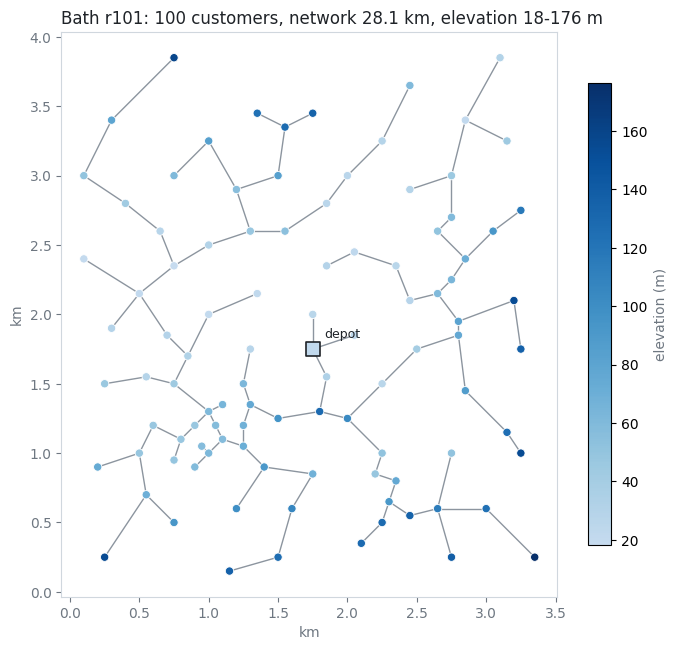

In [5]:
plot_mst("Bath", "r101")
plt.show()

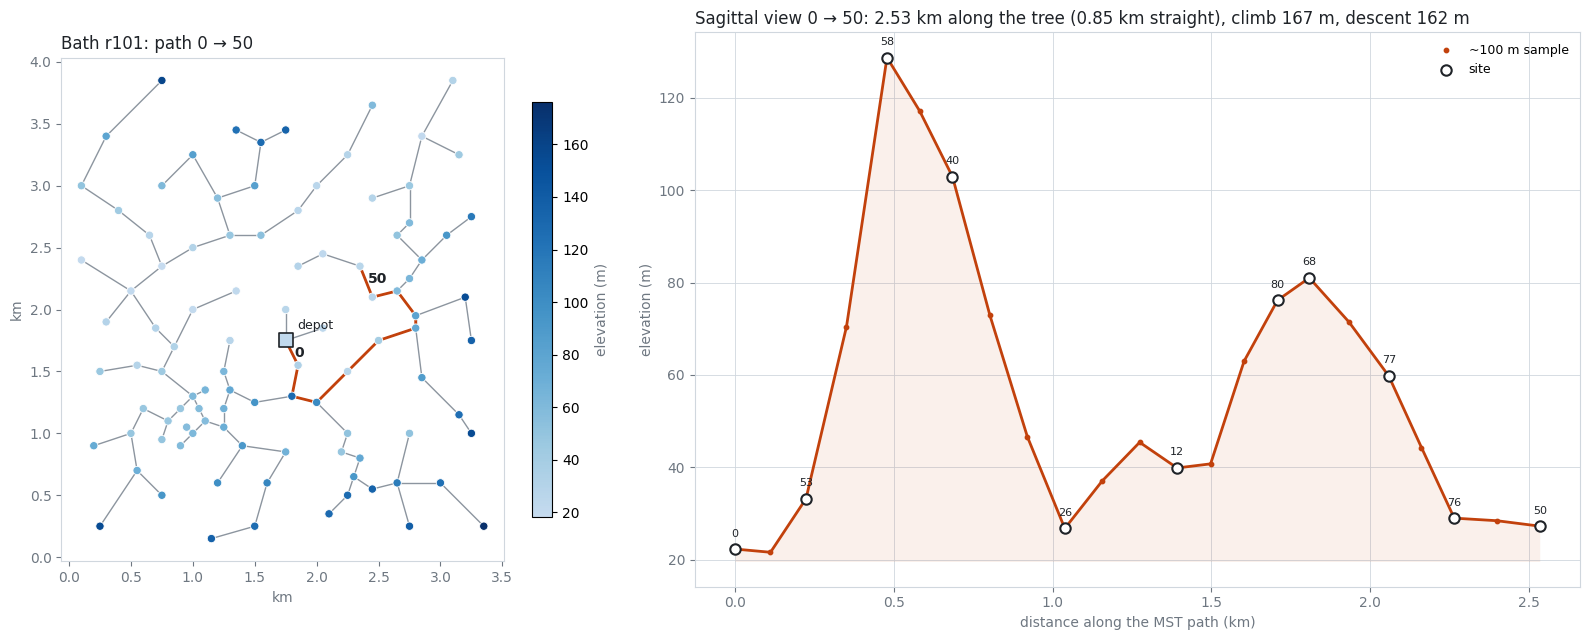

path_km                2.53
straight_km            0.85
sites_on_path          9.00
climb_m              166.78
descent_m            161.83
net_m                  4.95
steepest_up_pct       45.66
steepest_down_pct    -25.46
dtype: float64

In [6]:
plot_profile("Bath", "r101", 0, 50)

Between two customers. When the path doubles back through the tree, the distance along it is much
longer than the straight line.

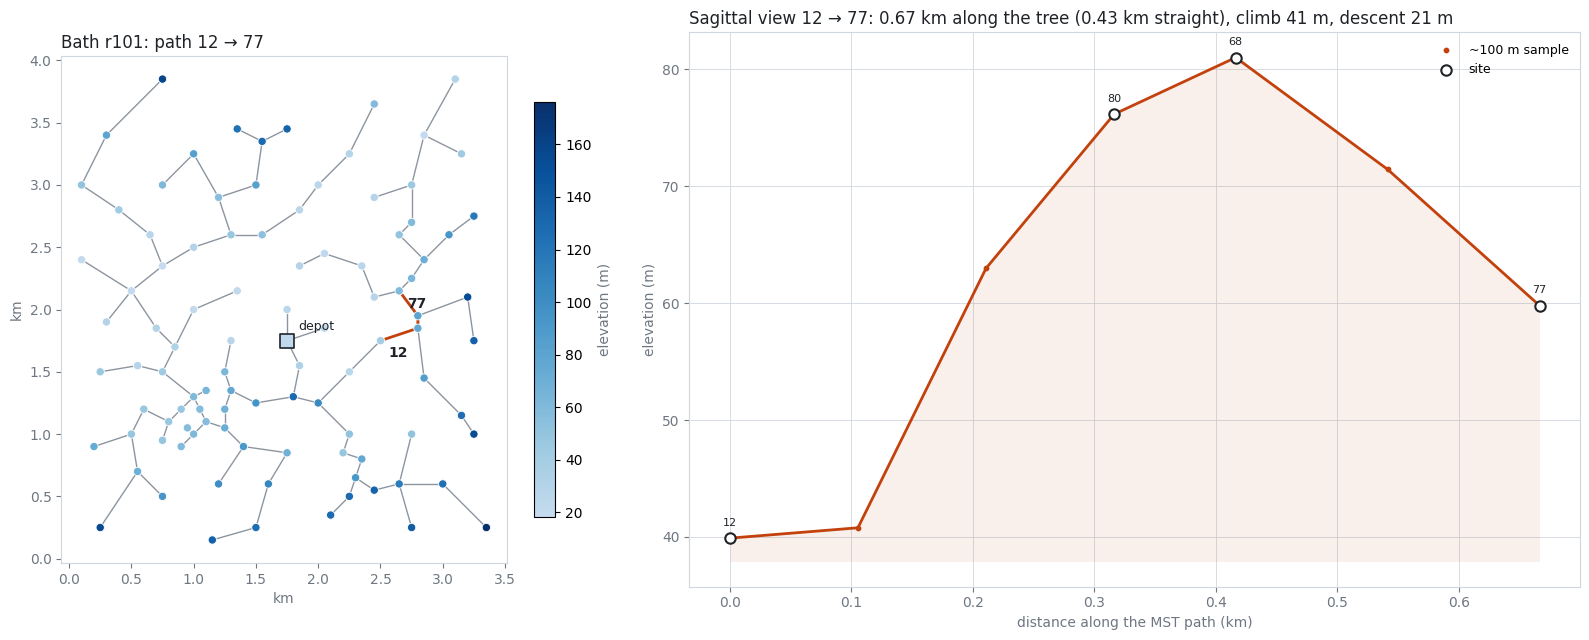

path_km               0.67
straight_km           0.43
sites_on_path         2.00
climb_m              41.13
descent_m            21.22
net_m                19.91
steepest_up_pct      21.07
steepest_down_pct    -9.32
dtype: float64

In [7]:
plot_profile("Bath", "r101", 12, 77)

The same layout and path in a flat city: Cambridge against Bath.

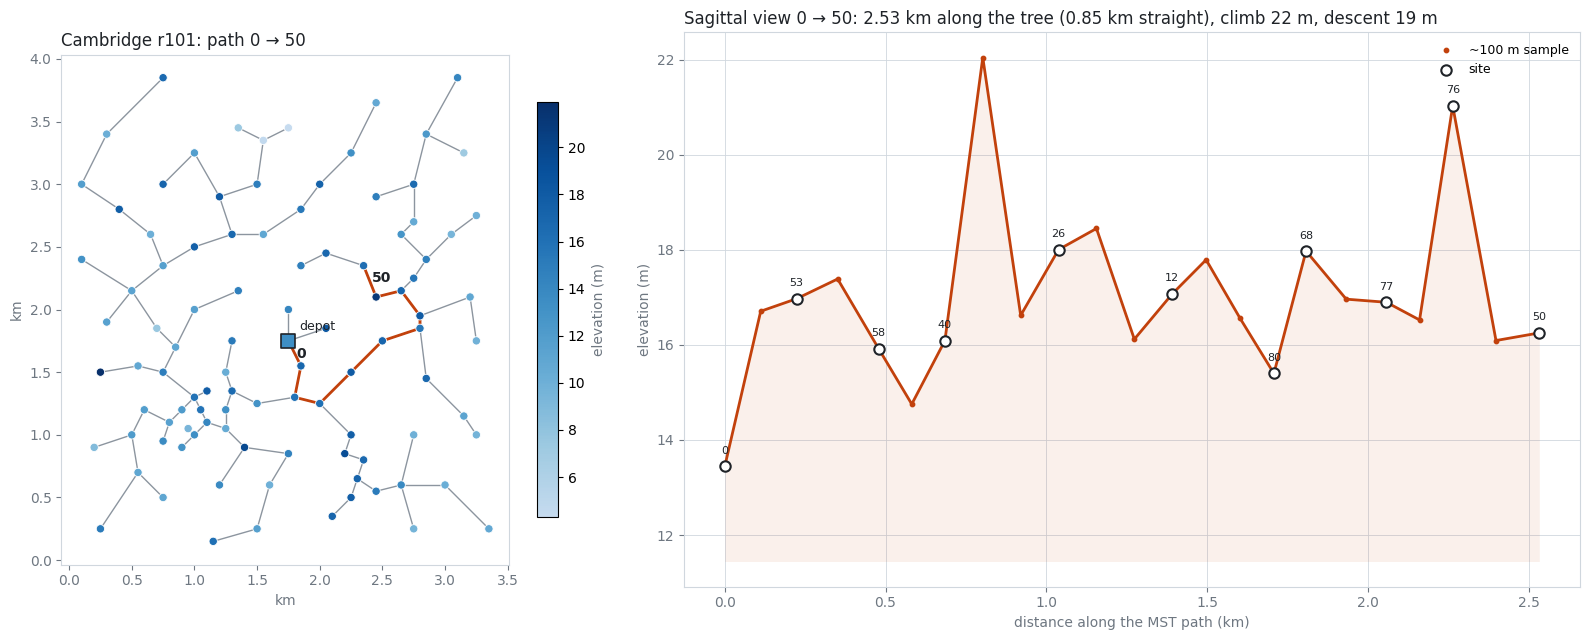

path_km               2.53
straight_km           0.85
sites_on_path         9.00
climb_m              21.97
descent_m            19.16
net_m                 2.81
steepest_up_pct       5.05
steepest_down_pct    -4.60
dtype: float64

In [8]:
plot_profile("Cambridge", "r101", 0, 50)

## Extended instances

r101 plus 100 stores. The original roads (darker) are unchanged, and each added store (triangle) hangs off
the nearest node on a spur.

['c107', 'c108', 'c109', 'r101', 'r101_200', 'r104', 'r104_200', 'r105', 'r105_200', 'r204', 'r204_200', 'r205', 'r205_200', 'r208', 'r208_200', 'rc101', 'rc104', 'rc105', 'rc107', 'rc201', 'rc204', 'rc207']


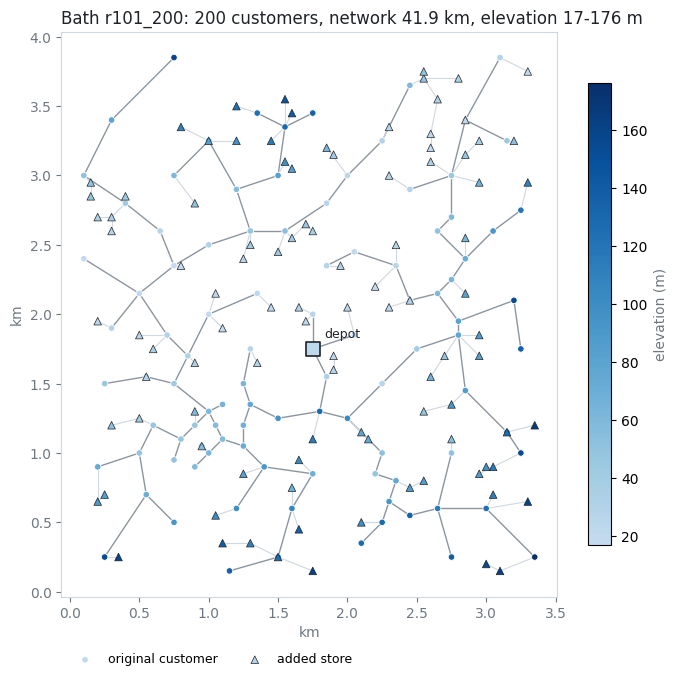

In [9]:
print(benchmarks("Bath"))
plot_mst("Bath", "r101_200")
plt.show()

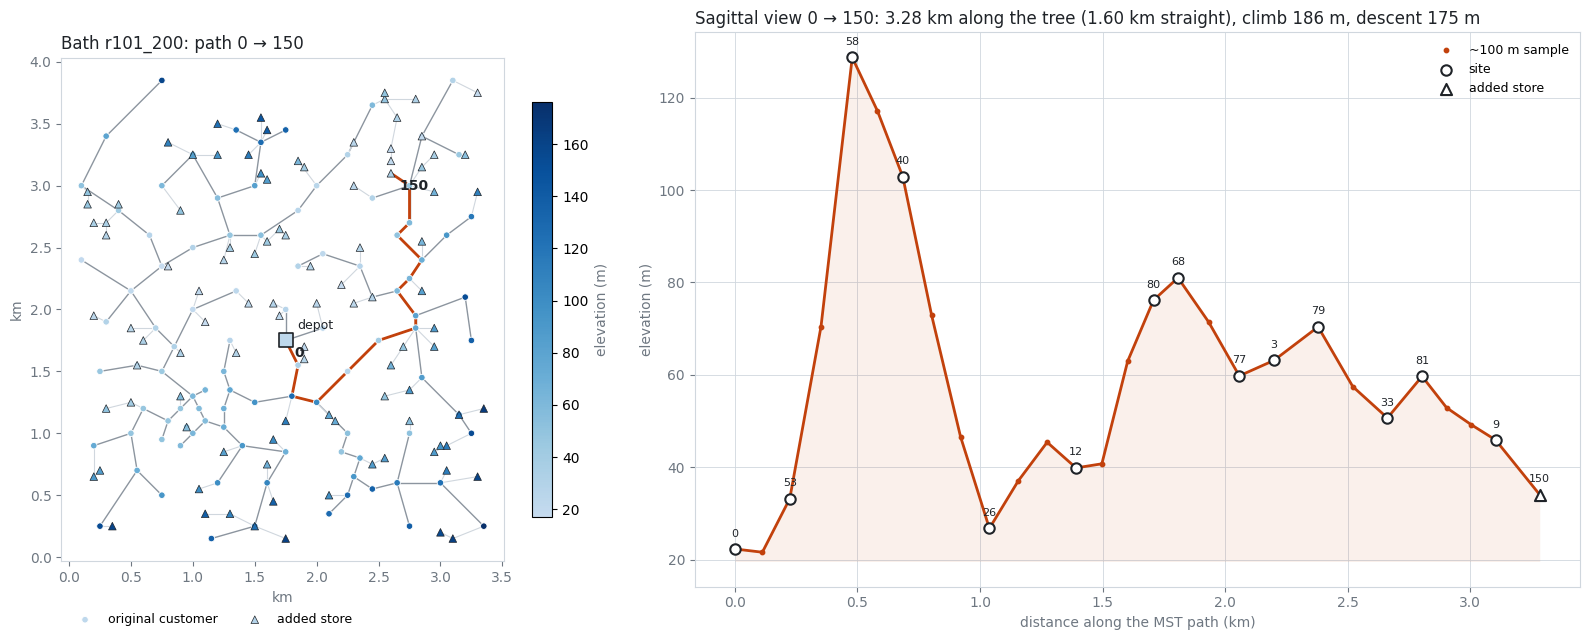

path_km                3.28
straight_km            1.60
sites_on_path         13.00
climb_m              186.40
descent_m            174.67
net_m                 11.73
steepest_up_pct       45.66
steepest_down_pct    -25.46
dtype: float64

In [10]:
plot_profile("Bath", "r101_200", 0, 150)

## Your own

Change the arguments: `plot_profile(city, benchmark, a, b)`.

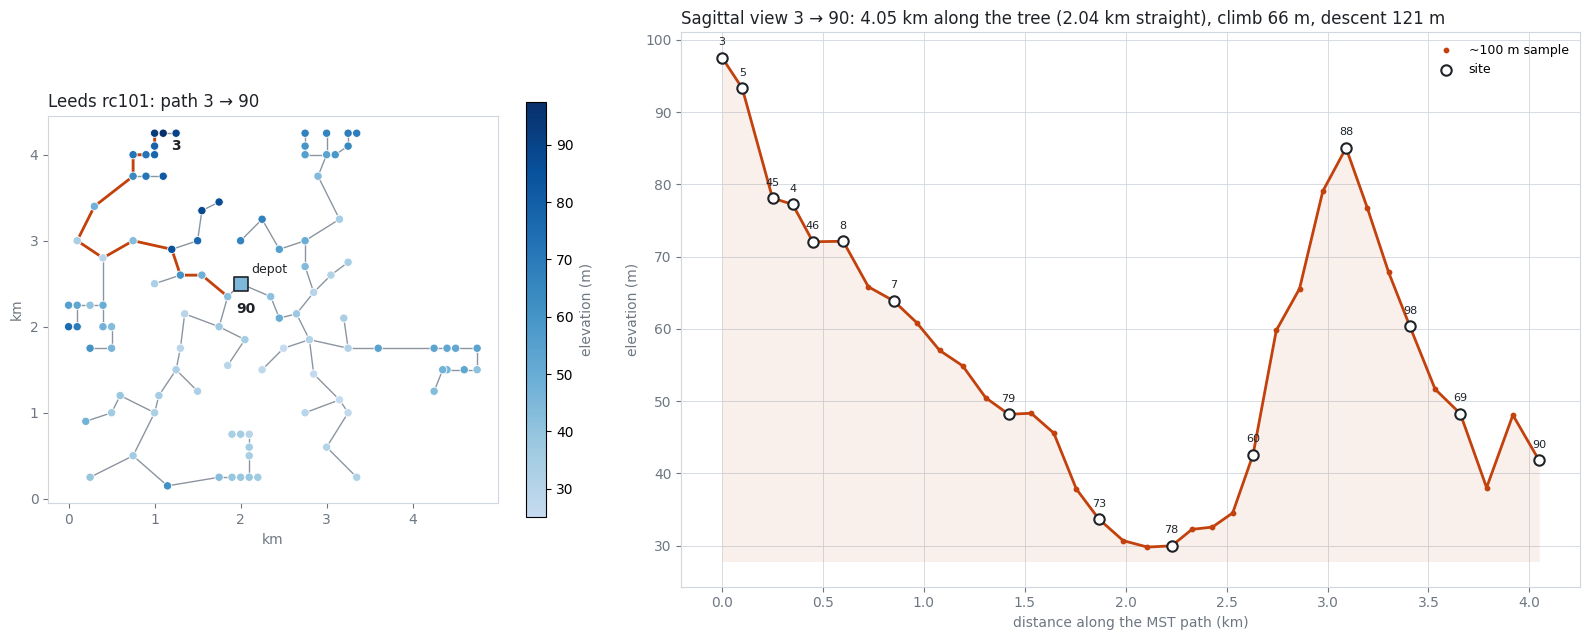

path_km                4.05
straight_km            2.04
sites_on_path         13.00
climb_m               65.51
descent_m            121.28
net_m                -55.77
steepest_up_pct       14.94
steepest_down_pct    -10.14
dtype: float64

In [11]:
plot_profile("Leeds", "rc101", 3, 90)